## Introduction to Quantum Computing: Labs

### Solution for Lab 6: Logical Queries

In this lab, we will first explore how classical logical operations such as AND, OR, and XOR can be implemented on a quantum computer. In particular, we will use the **X gate**, the **CX gate** (controlled NOT gate), and the **CCX gate** (Toffoli gate).

We will then use these building blocks to implement more complex logical queries. Finally, we will formulate the logical conditions of a simplified Sudoku and learn how to implement these queries on a quantum computer.

As a reminder, we briefly summarize the most important gates below.

#### CX or CNOT Gate

The CX gate acts on two qubits: a control qubit and a target qubit. The target qubit is flipped by an X gate if and only if the control qubit is in the state $|1\rangle$. If the control qubit is in the state $|0\rangle$, the target qubit remains unchanged.

Its action on the basis states is:

$$
|00\rangle \mapsto |00\rangle
\qquad
|01\rangle \mapsto |01\rangle
\qquad
|10\rangle \mapsto |11\rangle
\qquad
|11\rangle \mapsto |10\rangle
$$

#### CCX or Toffoli Gate

The CCX gate (Toffoli gate) acts on three qubits: two control qubits and a target qubit. The target qubit is flipped if and only if both control qubits are in the state $|1\rangle$.

The following cases are particularly relevant for its logical function:

$$
|110\rangle \mapsto |111\rangle
$$

$$
|111\rangle \mapsto |110\rangle
$$

In all other cases, the quantum state remains unchanged:

$$
|000\rangle \mapsto |000\rangle
\qquad
|100\rangle \mapsto |100\rangle
\qquad
|010\rangle \mapsto |010\rangle
\qquad \ldots
$$

Intuitively, the Toffoli gate corresponds to an AND operation on the control qubits that controls the target qubit.

In [18]:
import numpy as np
from qiskit import QuantumCircuit
from qc_lecture_tools.statevector import sv_state

### Exercise 1: Implementation of Classical Logic Gates

**Goal:** Implement the classical gates **AND, XOR, OR, NAND**, as well as an **equality check (=)**, using quantum gates.

We will use three qubits:

- Qubits 0 and 1 serve as the **input (A and B)**.
- Qubit 2 serves as the **output**, storing the result of the operation.

To test the gates, we use an input state in superposition so that we can examine all possible input combinations at once:

$$\ket{\Psi} = \frac{1}{2} (\ket{000} + \ket{010} + \ket{100} + \ket{110})$$

*Hint: The third qubit always starts in $\ket{0}$.*

**Truth tables:** The logic gates are defined as follows:

<table>
<tr>
<td>

**AND**

|  A |  B |  A AND B |
|---------|---------|------------------|
|    0    |    0    |        0         |
|    0    |    1    |        0         |
|    1    |    0    |        0         |
|    1    |    1    |        1         |

</td>
<td>

**XOR**

|  A |  B |  A XOR B |
|---------|---------|------------------|
|    0    |    0    |        0         |
|    0    |    1    |        1         |
|    1    |    0    |        1         |
|    1    |    1    |        0         |

</td>
<td>

**OR**

|  A |  B |  A OR B  |
|---------|---------|------------------|
|    0    |    0    |        0         |
|    0    |    1    |        1         |
|    1    |    0    |        1         |
|    1    |    1    |        1         |

</td>
<td>

**NAND**

|  A |  B |  A NAND B|
|---------|---------|------------------|
|    0    |    0    |        1         |
|    0    |    1    |        1         |
|    1    |    0    |        1         |
|    1    |    1    |        0         |

</td>
<td>

**Equality (=)**

|  A |  B |  A = B   |
|---------|---------|------------------|
|    0    |    0    |        1         |
|    0    |    1    |        0         |
|    1    |    0    |        0         |
|    1    |    1    |        1         |

</td>
</tr>
</table>

To verify the result, we can use the `compose` function. This allows us to place the test state (the superposition of the inputs) before our logic gate.

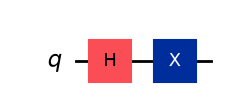

In [19]:
# Circuit 1
quantum_circuit1 = QuantumCircuit(1)
quantum_circuit1.h(0)

# Circuit 2
quantum_circuit2 = QuantumCircuit(1)
quantum_circuit2.x(0)

# Circuit 1 + circuit 2
quantum_circuit3 = quantum_circuit1.compose(quantum_circuit2)
display(quantum_circuit3.draw("mpl"))

To quickly verify the gate implementation, we use a uniform superposition of the first two qubits:

In [20]:
# First, define the circuit that prepares the superposition
qc_test = QuantumCircuit(3)
qc_test.h(0)
qc_test.h(1)
sv_state(qc_test, r"Input State: ")

<IPython.core.display.Math object>

**Exercise 1.1:** AND Gate

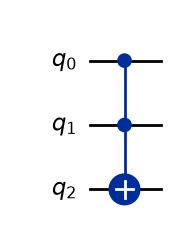

<IPython.core.display.Math object>

In [21]:
qc_and = QuantumCircuit(3)
qc_and.ccx(0, 1, 2)
display(qc_and.draw("mpl"))
sv_state(qc_test.compose(qc_and), r"Output State: ")

**Exercise 1.2:** XOR Gate

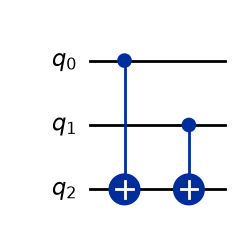

<IPython.core.display.Math object>

In [22]:
qc_xor = QuantumCircuit(3)
qc_xor.cx(0, 2)
qc_xor.cx(1, 2)
display(qc_xor.draw("mpl"))
sv_state(qc_test.compose(qc_xor), r"Output State: ")

**Exercise 1.3:** OR Gate

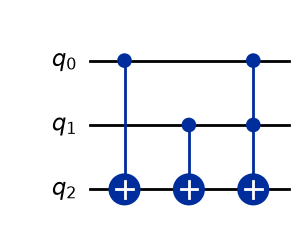

<IPython.core.display.Math object>

In [23]:
qc_or = QuantumCircuit(3)
qc_or.cx(0, 2)
qc_or.cx(1, 2)
qc_or.ccx(0, 1, 2)
display(qc_or.draw("mpl"))
sv_state(qc_test.compose(qc_or), r"Output State: ")

**Exercise 1.4:** NAND Gate

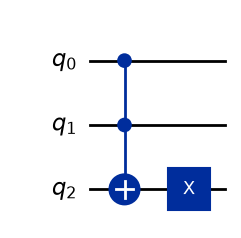

<IPython.core.display.Math object>

In [24]:
qc_nand = QuantumCircuit(3)
qc_nand.ccx(0, 1, 2)
qc_nand.x(2)
display(qc_nand.draw("mpl"))
sv_state(qc_test.compose(qc_nand), r"Output State: ")

**Exercise 1.5:** Equality Check (=)

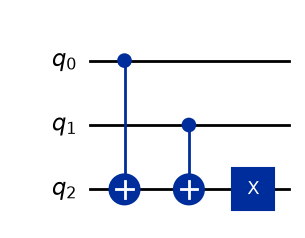

<IPython.core.display.Math object>

In [25]:
qc_eq = QuantumCircuit(3)
qc_eq.cx(0, 2)
qc_eq.cx(1, 2)
qc_eq.x(2)

display(qc_eq.draw("mpl"))
sv_state(qc_test.compose(qc_eq), r"Output State: ")

### Exercise 2: More Complex Logical Queries

Now we generalize this approach. We have data qubits and want to check a complex condition, storing the result in an additional qubit, also called an ancilla qubit.

**Example:** Check whether exactly one of two data qubits is set to 1 (equivalent to XOR).

In [26]:
qc_check = QuantumCircuit(3)
qc_check.cx(0, 2)
qc_check.cx(1, 2)

print("State after the check (qubit 2 stores the result):")
display(sv_state(qc_test.compose(qc_check)))

State after the check (qubit 2 stores the result):


<IPython.core.display.Math object>

**Exercise 2.1:** Implement a query for two data qubits ($q_0, q_1$) that writes a $\ket{1}$ to qubit 2 only when both data qubits are in the state $\ket{0}$.
(That is, $\ket{000} \rightarrow \ket{001}$; all other inputs produce an output of $0$.)

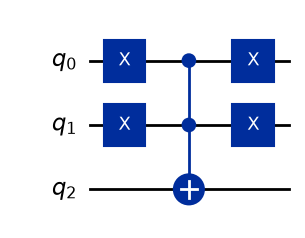

<IPython.core.display.Math object>

In [27]:
qc_21 = QuantumCircuit(3)
qc_21.x(0)
qc_21.x(1)
qc_21.ccx(0, 1, 2)
qc_21.x(0)
qc_21.x(1)
display(qc_21.draw("mpl"))
sv_state(qc_test.compose(qc_21), r"Output State: ")

**Exercise 2.2:** We have three data qubits ($q_0, q_1, q_2$). Implement a circuit that sets an ancilla qubit ($q_3$) to $\ket{1}$ when **both** of the following conditions are met:

1. Qubit 0 and qubit 1 are **not both** 1.
2. Qubit 1 and qubit 2 are **not both** 0.

The states that satisfy both conditions are: $001$, $010$, $011$, $101$.

**Hint:** You will need additional ancilla qubits to store intermediate results and then combine them using another gate.

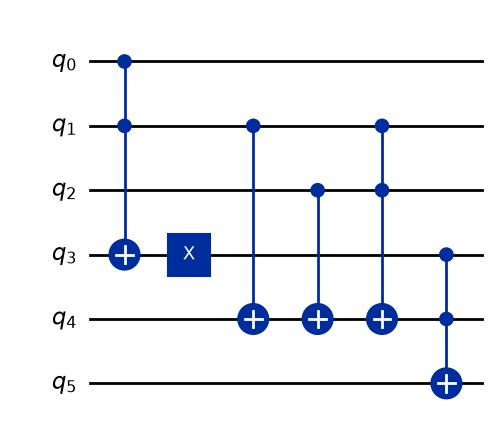

<IPython.core.display.Math object>

In [28]:
qc_test = QuantumCircuit(6)
qc_test.h(0)
qc_test.h(1)
qc_test.h(2)


qc_22 = QuantumCircuit(6)
# Store the result of query 1 in ancilla qubit 3
qc_22.ccx(0, 1, 3)
qc_22.x(3)
# Store the result of query 2 in ancilla qubit 4
qc_22.cx(1,4)
qc_22.cx(2,4)
qc_22.ccx(1, 2, 4)
# Store whether both queries return 1 in ancilla qubit 5
qc_22.ccx(3, 4, 5)

display(qc_22.draw("mpl"))
sv_state(qc_test.compose(qc_22), r"Output State: ")

### Exercise 3: Sudoku Logic

Consider the following 2x2 Sudoku (the order of the numbers does not matter):

| ? | 4 |
|---|---|
| **2** | ? |

A valid solution requires each number to appear only once when filling the empty cells. We omit additional numbers or boxes, as otherwise too many bits would quickly be needed.

We represent the numbers using two bits:

- 1 &rarr; 00
- 2 &rarr; 01
- 3 &rarr; 10
- 4 &rarr; 11

The goal is to implement a quantum query that sets a final ancilla qubit to $\ket{1}$ when the two unknown cells contain a valid solution.

**Conditions for a valid solution:**

1. Neither unknown number may be 2 ($01$) or 4 ($11$).
2. The unknown numbers must be different from each other.

It is clear that the missing numbers are 1 and 3. However, the query should not simply check whether the bitstring $q_0q_1q_2q_3$ is equal to 1000 or 0010, since this would require knowing the solution in advance.

**Exercise 3.1:**
Implement a query for two qubits ($q_0, q_1$) that checks whether the encoded number is **not equal to 2** ($01$). Store the result in an ancilla qubit. To test the query, create a uniform superposition of all four possible states in the first two qubits and store the result in a third qubit.

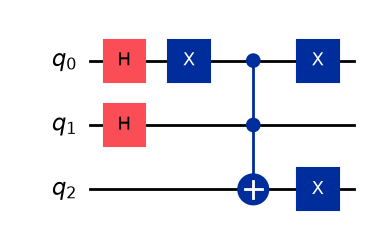

<IPython.core.display.Math object>

In [29]:
qc_31 = QuantumCircuit(3)
qc_31.h(0)
qc_31.h(1)

# Implement the query: "Are the first two bits different from 01?"
qc_31.x(0)
qc_31.ccx(0, 1, 2)
qc_31.x(0)
qc_31.x(2)

display(qc_31.draw("mpl"))
sv_state(qc_31, r"Output State: ")


**Exercise 3.2:**
Implement a query for two qubits ($q_0, q_1$) that checks whether the encoded number is **not equal to 4** ($11$). Store the result in an ancilla qubit. Follow the same approach as in Exercise 3.1.

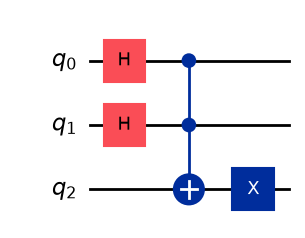

<IPython.core.display.Math object>

In [30]:
qc_32 = QuantumCircuit(3)
qc_32.h(0)
qc_32.h(1)

# Implement the query: "Are the first two bits different from 11?"
qc_32.ccx(0, 1, 2)
qc_32.x(2)

display(qc_32.draw("mpl"))
sv_state(qc_32, r"Output State: ")


**Exercise 3.3: Combining Multiple Conditions**

For the first unknown number (qubits $q_0, q_1$), check whether it is neither 2 (01) nor 4 (11). Store the results of the individual checks in ancilla qubits, then combine them into a third ancilla qubit for the combined query.
As before, create a superposition of the four possible numbers (1-4) in the first two qubits and apply the query to this state.

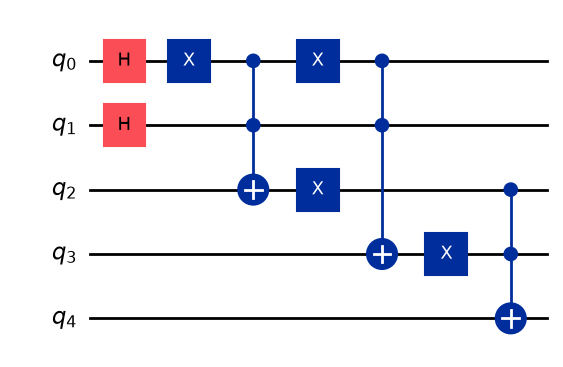

<IPython.core.display.Math object>

In [31]:
qc_33 = QuantumCircuit(5)
qc_33.h(0)
qc_33.h(1)

qc_33.x(0)
qc_33.ccx(0, 1, 2)
qc_33.x(0)
qc_33.x(2)

qc_33.ccx(0, 1, 3)
qc_33.x(3)

qc_33.ccx(2, 3, 4)

display(qc_33.draw("mpl"))
sv_state(qc_33, r"Output State: ")

**Exercise 3.4:** We still need to check whether the two numbers are different. The comparison works best bit by bit, comparing the first bits of the two numbers and then their second bits.

This means that we now have 4 data qubits: $\ket{q_0q_1 ~ q_2q_3}$.

Determine how many additional ancilla qubits you need for this query and implement it.

With so many qubits and states, displaying all states becomes difficult to read. The following helper function prints all states with the first two bits grouped as number 1 and the next two bits as number 2.

In [32]:
# Helper function for displaying the statevector
from qc_lecture_tools.statevector import sv_array
import numpy as np

def print_sudoku_states(quantum_circuit):
    statevector = sv_array(quantum_circuit)
    print("Bitstrings in the quantum state with nonzero amplitudes:")
    for i, amplitude in enumerate(statevector):
        if np.abs(amplitude) > 1e-10:
            # Convert integer values to bitstrings
            bitstr = format(i, f"0{quantum_circuit.num_qubits}b")
            print(f"{bitstr[:2]} {bitstr[2:4]} {bitstr[4:-1]} {bitstr[-1]}  ")

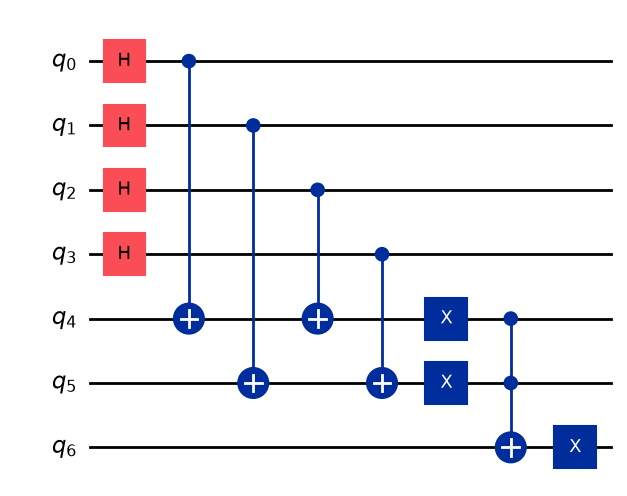

Bitstrings in the quantum state with nonzero amplitudes:
00 00 11 0  
00 01 10 1  
00 10 01 1  
00 11 00 1  
01 00 10 1  
01 01 11 0  
01 10 00 1  
01 11 01 1  
10 00 01 1  
10 01 00 1  
10 10 11 0  
10 11 10 1  
11 00 00 1  
11 01 01 1  
11 10 10 1  
11 11 11 0  


In [33]:
qc_34 = QuantumCircuit(7)

qc_34.h([0,1,2,3])

# Check whether the first bits of the two numbers are equal
qc_34.cx(0,4)  
qc_34.cx(2,4)
qc_34.x(4)

# Check whether the second bits of the two numbers are equal
qc_34.cx(1,5)
qc_34.cx(3,5)
qc_34.x(5)

# Check whether both previous queries are satisfied
qc_34.ccx(4,5,6)

# Invert the equality result to check for inequality
qc_34.x(6)

display(qc_34.draw("mpl"))
print_sudoku_states(qc_34)

### Bonus Exercise: Complete Sudoku Check

We now have 4 data qubits: $\ket{q_0 q_1}$ (number 1) and $\ket{q_2 q_3}$ (number 2).

Implement the complete check:

- Number 1 is neither 2 nor 4.
- Number 2 is neither 2 nor 4.
- Number 1 $\neq$ number 2.

You will need many ancilla qubits!
One possible approach is to use equality checks for all conditions, combine them using AND, and negate the result with a NOT operation at the end.

Use the helper function `print_sudoku_states` to display only the states for which the final result qubit is $\ket{1}$.

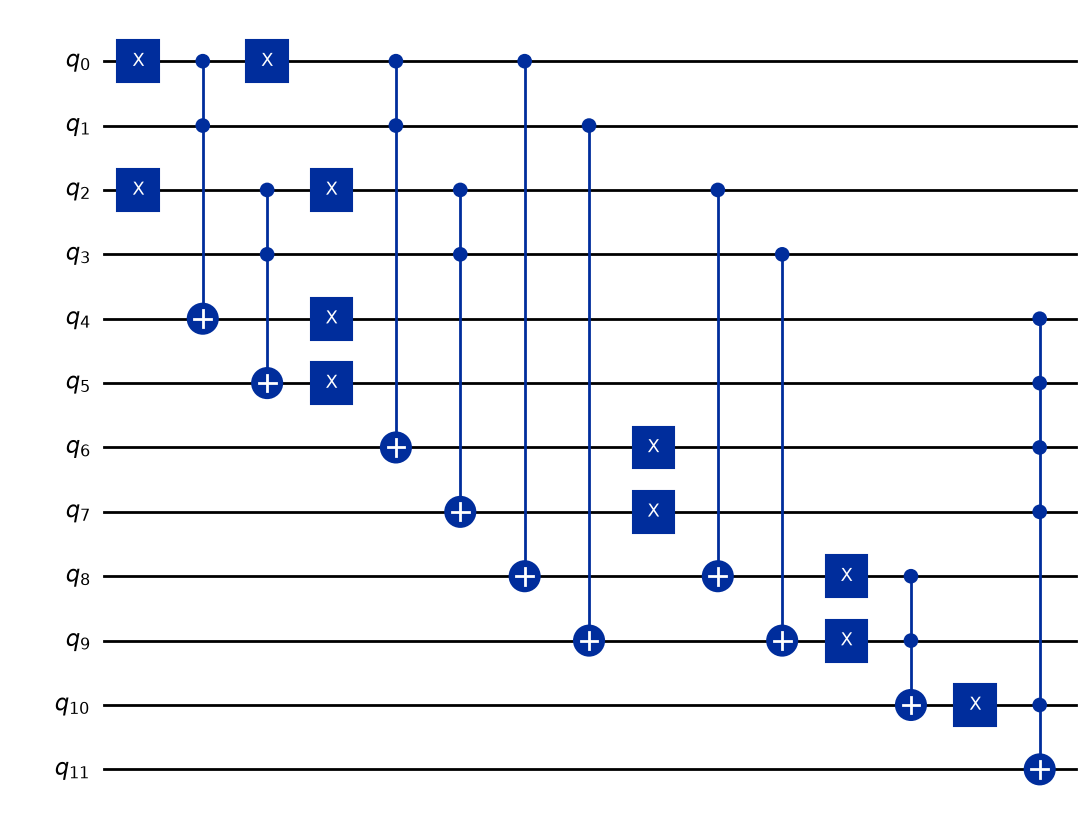

Bitstrings in the quantum state with nonzero amplitudes:
00 00 1111110 0  
00 01 1011101 0  
00 10 1111011 1  
00 11 1110001 0  
01 00 0111101 0  
01 01 0011110 0  
01 10 0111001 0  
01 11 0110011 0  
10 00 1111011 1  
10 01 1011001 0  
10 10 1111110 0  
10 11 1110101 0  
11 00 1101001 0  
11 01 1001011 0  
11 10 1101101 0  
11 11 1100110 0  


In [34]:
qc_data = QuantumCircuit(12)

# Qubits 0+1 -> first unknown number
qc_data.h(0)
qc_data.h(1)
# Qubits 2+3 -> second unknown number
qc_data.h(2)
qc_data.h(3)

# Start implementing the query
qc_check = QuantumCircuit(12)

# Ancilla 1 (qubit 4) checks q0q1 == 01
qc_check.x(0)
qc_check.ccx(0, 1, 4)
qc_check.x(0)

# Ancilla 2 (qubit 5) checks q2q3 == 01
qc_check.x(2)
qc_check.ccx(2, 3, 5)
qc_check.x(2)

# Ancilla 3 (qubit 6) checks q0q1 == 11
qc_check.ccx(0, 1, 6)

# Ancilla 4 (qubit 7) checks q2q3 == 11
qc_check.ccx(2, 3, 7)


# Ancilla 5 (qubit 8) checks q0==q2
qc_check.cx(0, 8)
qc_check.cx(2, 8)
qc_check.x(8)

# Ancilla 6 (qubit 9) checks q1==q3
qc_check.cx(1, 9)
qc_check.cx(3, 9)
qc_check.x(9)

# Check whether both equality checks (ancillas 5 and 6) are satisfied
qc_check.ccx(8, 9, 10)

# Invert all query results -> a valid solution has all results equal to 1
qc_check.x([4, 5, 6, 7, 10])

# Multi-controlled CNOT with the oracle qubit as the target
qc_check.mcx([4, 5, 6, 7, 10], 11)

display(qc_check.draw('mpl'))

# Display the bitstrings in the quantum state with nonzero amplitudes
# Format the output with spaces between the numbers and the final result qubit
print_sudoku_states(qc_data.compose(qc_check))